In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("Unemployment in India.csv")

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 768
Columns: 7


In [4]:
df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [5]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [6]:
df.columns = df.columns.str.strip()

df.columns

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

In [7]:
df.rename(columns={
    'Region': 'Region',
    'Date': 'Date',
    'Frequency': 'Frequency',
    'Estimated Unemployment Rate (%)': 'Unemployment_Rate',
    'Estimated Employed': 'Employed',
    'Estimated Labour Participation Rate (%)': 'Labour_Participation_Rate'
}, inplace=True)

In [8]:
df.isnull().sum()
(df.isnull().sum() / len(df)) * 100

Region                       3.645833
Date                         3.645833
Frequency                    3.645833
Unemployment_Rate            3.645833
Employed                     3.645833
Labour_Participation_Rate    3.645833
Area                         3.645833
dtype: float64

In [9]:
df = df.dropna()
df.isnull().sum()

Region                       0
Date                         0
Frequency                    0
Unemployment_Rate            0
Employed                     0
Labour_Participation_Rate    0
Area                         0
dtype: int64

In [10]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df['Date'].head()
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%B')

In [11]:
region_avg = (
    df.groupby('Region')['Unemployment_Rate']
      .mean()
      .sort_values(ascending=False)
)

region_avg

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Unemployment_Rate, dtype: float64

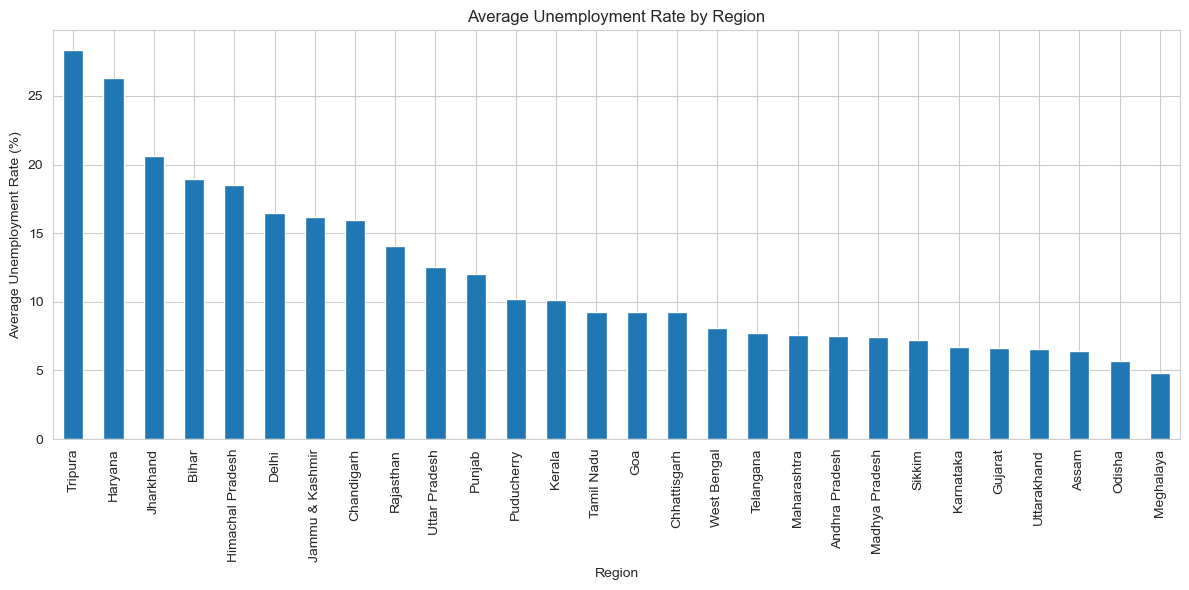

In [12]:
plt.figure(figsize=(12, 6))

region_avg.plot(kind='bar')

plt.title('Average Unemployment Rate by Region')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [13]:
monthly_avg = (
    df.groupby('Month_Name')['Unemployment_Rate']
      .mean()
)

monthly_avg

Month_Name
April        23.641569
August        9.637925
December      9.497358
February      9.964717
January       9.950755
July          9.033889
June         10.553462
March        10.700577
May          16.646190
November      9.868364
October       9.900909
September     9.051731
Name: Unemployment_Rate, dtype: float64

In [14]:
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_avg = monthly_avg.reindex(month_order)

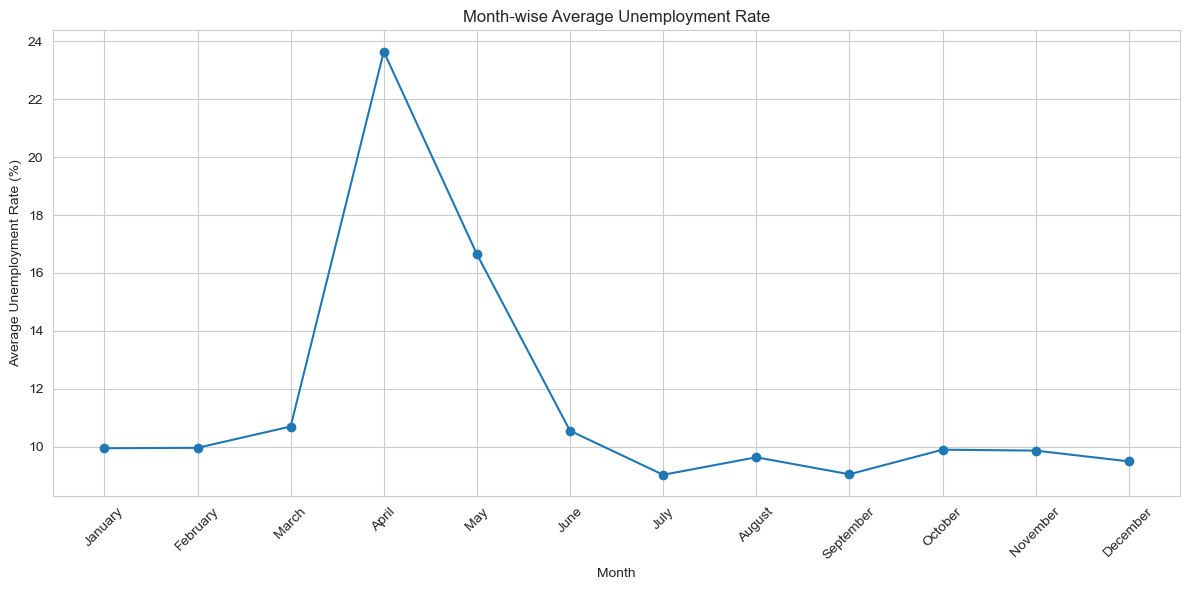

In [15]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker='o'
)

plt.title('Month-wise Average Unemployment Rate')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [16]:
df['Region'].unique()
selected_regions = ['Maharashtra', 'Delhi', 'West Bengal']
df['Region'].unique()

array(['Andhra Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Goa',
       'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir',
       'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh',
       'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab',
       'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura',
       'Uttar Pradesh', 'Uttarakhand', 'West Bengal', 'Chandigarh'],
      dtype=object)

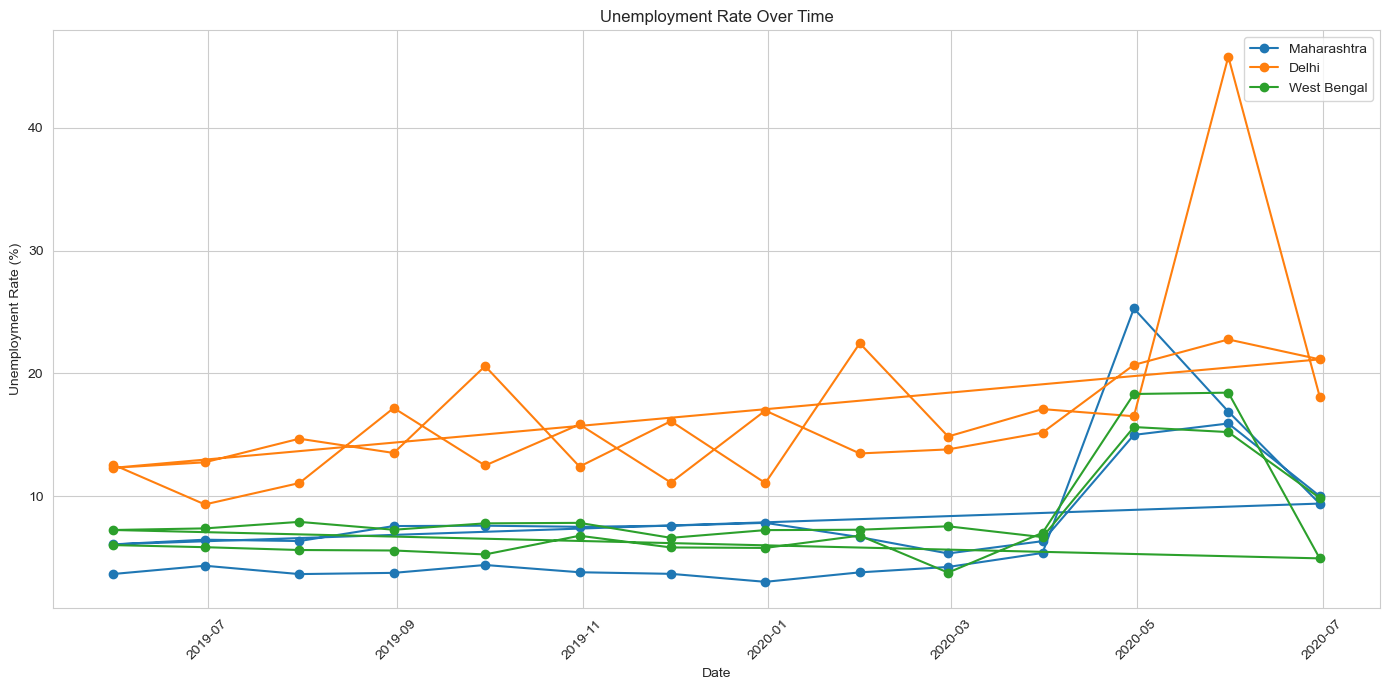

In [17]:
plt.figure(figsize=(14, 7))

for region in selected_regions:
    region_data = df[df['Region'] == region]
    
    plt.plot(
        region_data['Date'],
        region_data['Unemployment_Rate'],
        marker='o',
        label=region
    )

plt.title('Unemployment Rate Over Time')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [18]:
top_10 = (
    df.groupby('Region')['Unemployment_Rate']
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

top_10

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Unemployment_Rate, dtype: float64

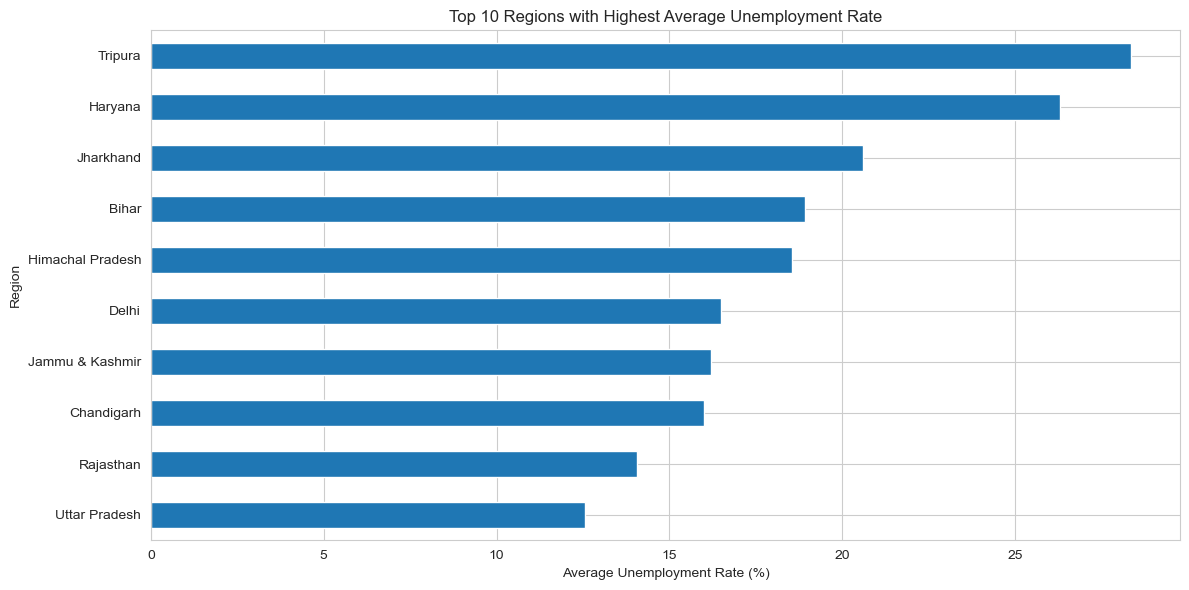

In [19]:
plt.figure(figsize=(12, 6))

top_10.sort_values().plot(kind='barh')

plt.title('Top 10 Regions with Highest Average Unemployment Rate')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('Region')

plt.tight_layout()
plt.show()

In [20]:
correlation_data = df[
    ['Unemployment_Rate',
     'Employed',
     'Labour_Participation_Rate']
]

In [21]:
correlation_matrix = correlation_data.corr()

correlation_matrix

,Unemployment_Rate,Employed,Labour_Participation_Rate
Unemployment_Rate,1.000000,-0.222876,0.002558
Employed,-0.222876,1.000000,0.011300
Labour_Participation_Rate,0.002558,0.011300,1.000000


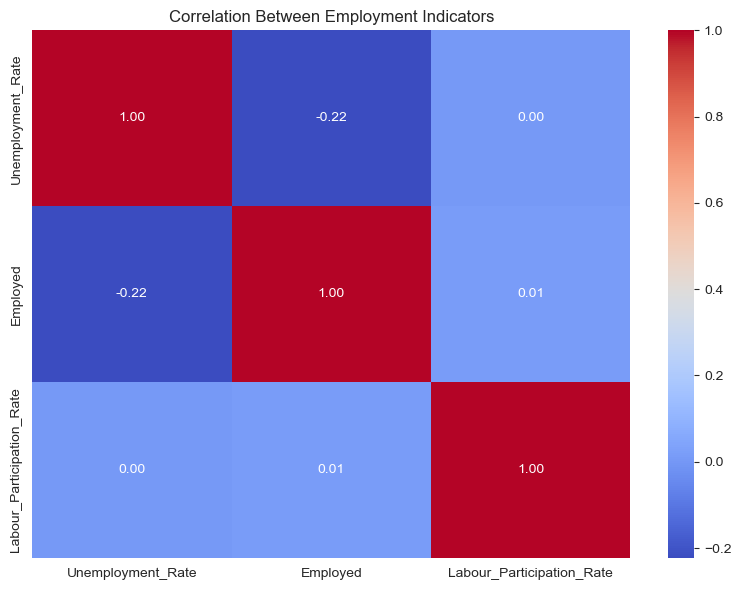

In [22]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Employment Indicators')

plt.tight_layout()
plt.show()

In [23]:
print("Minimum date:", df['Date'].min())
print("Maximum date:", df['Date'].max())
covid_date = pd.Timestamp('2020-03-01')

df['Period'] = np.where(
    df['Date'] < covid_date,
    'Pre-COVID',
    'COVID/Post-COVID'
)

Minimum date: 2019-05-31 00:00:00
Maximum date: 2020-06-30 00:00:00


In [24]:
df['Period'].value_counts()

Period
Pre-COVID           536
COVID/Post-COVID    204
Name: count, dtype: int64

In [25]:
period_comparison = (
    df.groupby('Period')[
        ['Unemployment_Rate',
         'Employed',
         'Labour_Participation_Rate']
    ]
    .mean()
)

period_comparison

,Unemployment_Rate,Employed,Labour_Participation_Rate
Period,,,
COVID/Post-COVID,17.774363,6.517203e+06,39.330049
Pre-COVID,9.509534,7.466028e+06,43.886119


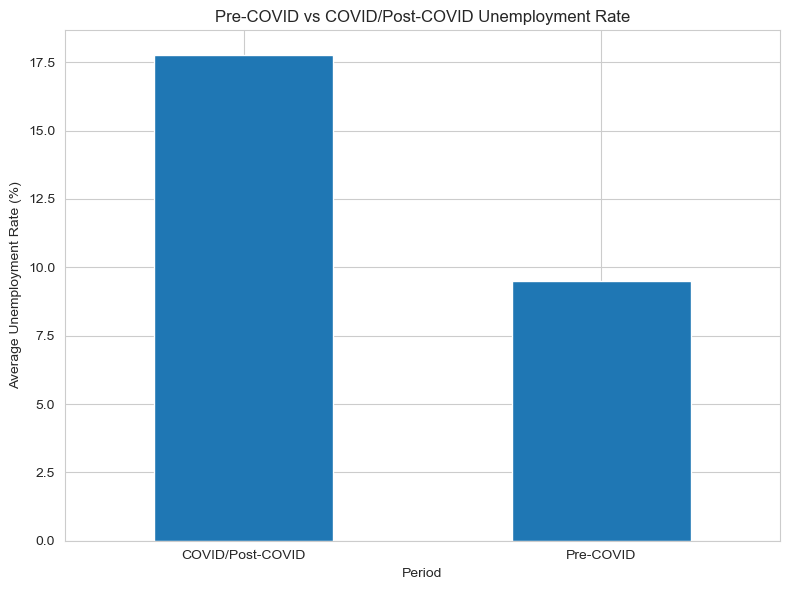

In [26]:
period_comparison['Unemployment_Rate'].plot(
    kind='bar',
    figsize=(8, 6)
)

plt.title('Pre-COVID vs COVID/Post-COVID Unemployment Rate')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

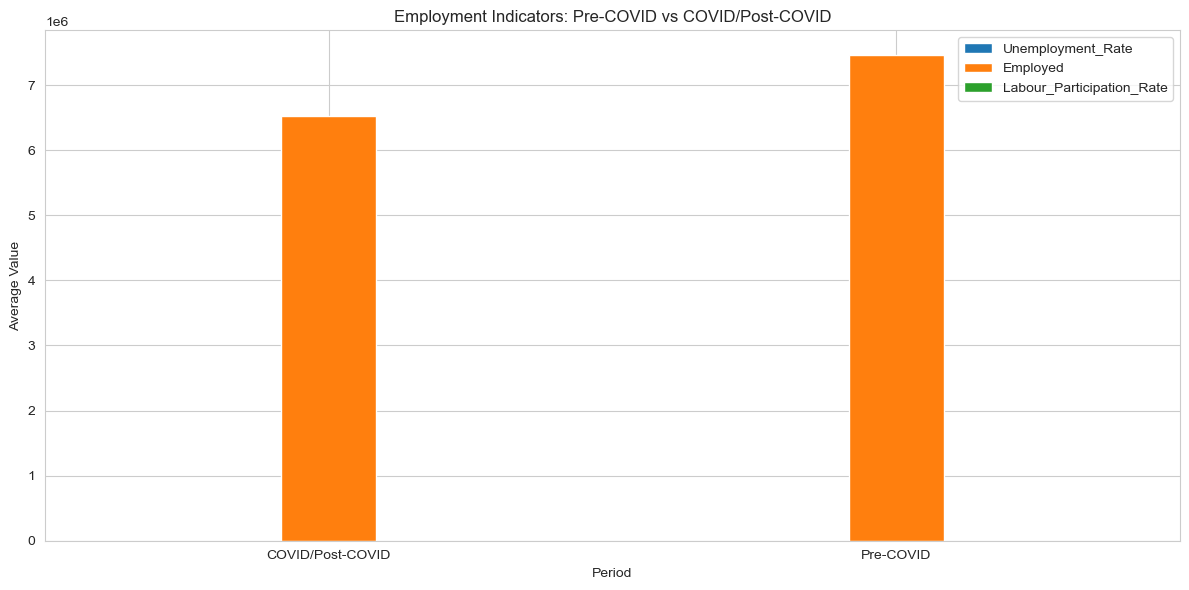

In [27]:
period_comparison.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Employment Indicators: Pre-COVID vs COVID/Post-COVID')
plt.xlabel('Period')
plt.ylabel('Average Value')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

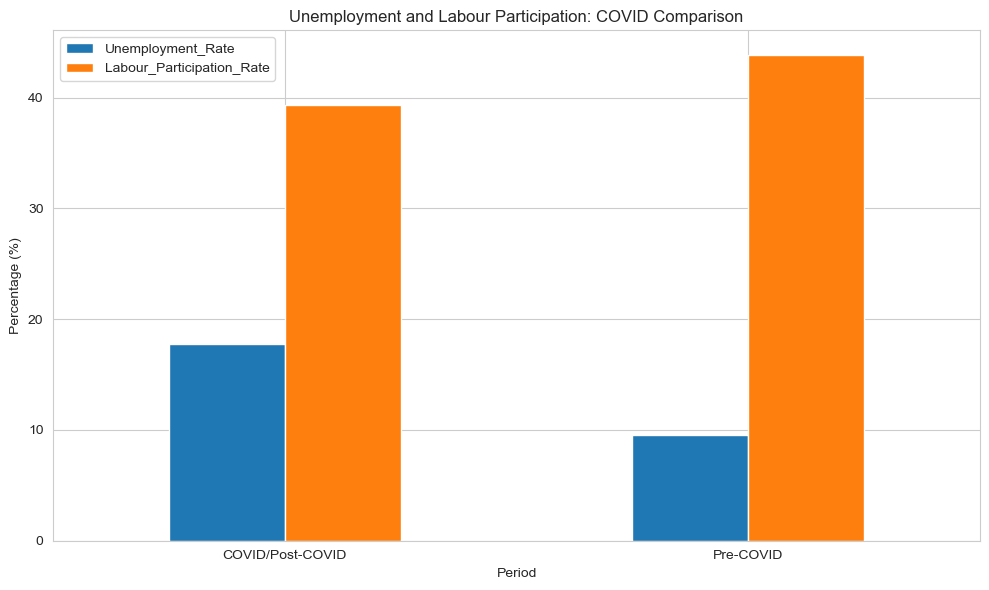

In [28]:
percentage_data = period_comparison[
    ['Unemployment_Rate', 'Labour_Participation_Rate']
]

percentage_data.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Unemployment and Labour Participation: COVID Comparison')
plt.xlabel('Period')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

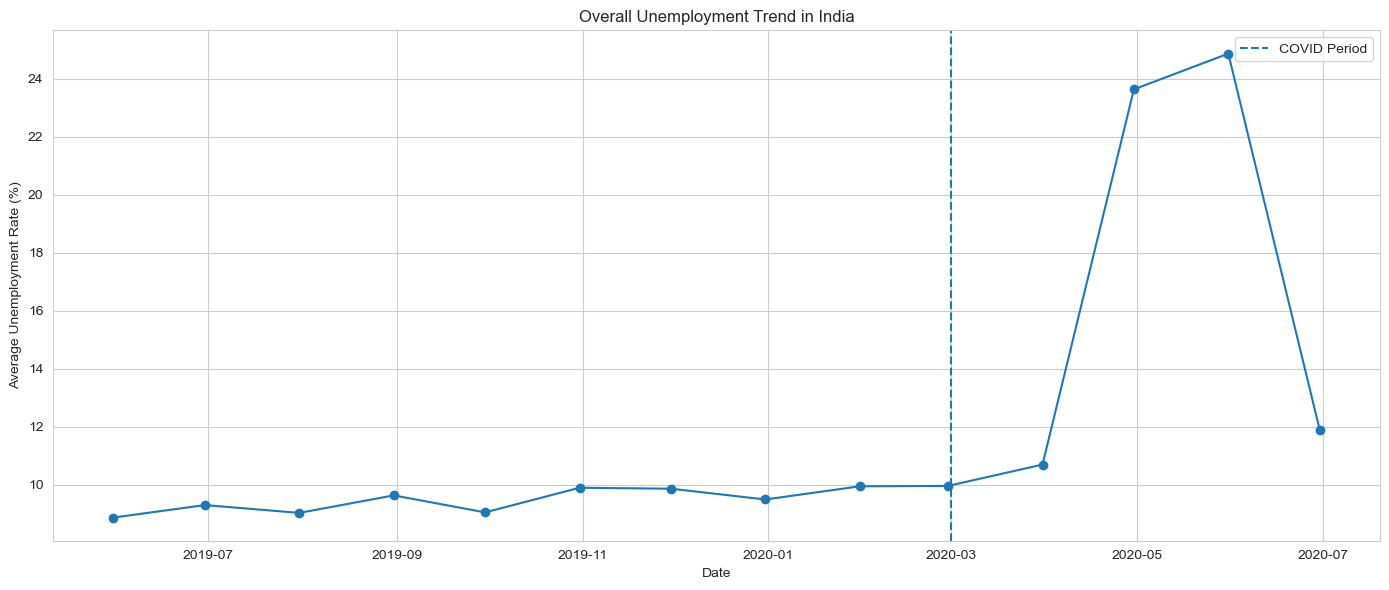

In [29]:
overall_trend = (
    df.groupby('Date')['Unemployment_Rate']
      .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    overall_trend.index,
    overall_trend.values,
    marker='o'
)

plt.axvline(
    pd.Timestamp('2020-03-01'),
    linestyle='--',
    label='COVID Period'
)

plt.title('Overall Unemployment Trend in India')
plt.xlabel('Date')
plt.ylabel('Average Unemployment Rate (%)')
plt.legend()

plt.tight_layout()
plt.show()